# Regression with the other Methods (Random Forest, Light GBM, XGBoost, SVR) — WPPSI-III IQ from Neonatal ECG/HRV

Template for regressing WPPSI-III IQ scores (Full-Scale \`Note composite_WPPSI\`, Verbal \`NS Verb._WPPSI\`, Performance \`NS Perf._WPPSI\`, …) from neonatal linear + nonlinear HRV features (AuBE cohort, M0 recordings only).

Data source: the cleaned + merged table produced by data_preprocessing.py / data_merge.py / data_features.py (see GroupA/daniela/docs/Important milestones.md).

Use data/clean_data_shifted/ (automatic column-shift repair via fix_shifted_rows(), SHIFT=2) or data/clean_data_m_shifted/ (manual shift repair).

See Group A/dataset.md for the full data dictionary and merge rules.


In [17]:
# --------------------------------------------------------------
# 1. Imports
# --------------------------------------------------------------

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn
from sklearn.model_selection import (train_test_split, KFold, RepeatedKFold,
                                     cross_val_score, cross_validate,
                                     cross_val_predict, GridSearchCV)
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)

# Models
from sklearn.linear_model import Ridge, Lasso, ElasticNet, BayesianRidge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

# Persistence
import joblib

# Plotting
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)


## 2. Load Data

Load the cleaned + merged dataset produced by the preprocessing pipeline
(`data_preprocessing.py` + `data_merge.py` + `data_features.py`).

- Cleaning: WPPSI empty-row removal, subject matching by NUMBER + DOB check,
  `Passage == "M0"` filtering, empty-cell subject removal across HRV files,
  removal of WPPSI-only subjects (see `GroupA/daniela/docs/Important milestones.md`).
- Column-shift repair: automatic via `fix_shifted_rows()` (`SHIFT=2`, `MISSING="-"`)
  in `clean_data_shifted/`; manual in `clean_data_m_shifted/`.
- Merge: linear + nonlinear HRV on `Monogramme` + `DDN` + `Passage`,
  then HRV + WPPSI on `Monogramme` + `DDN`.
- Features: constant and highly correlated (|r| > 0.95) features already removed.

Choose the cleaned source: `clean_data_shifted` (recommended) or `clean_data_m_shifted`.


In [18]:
# --------------------------------------------------------------
# Paths (relative to project root)
# --------------------------------------------------------------

CLEAN_SOURCE = 'clean_data_shifted'  # or 'clean_data_m_shifted'

# Resolve the data path robustly: try relative to CWD (project root)
# and relative to the notebook's own location (GroupA/daniela/ or GroupA/Jade/).
from pathlib import Path

candidate_paths = [
    Path(f'data/{CLEAN_SOURCE}/merged_dataset_features.csv'),  # run from project root
    Path(f'../../data/{CLEAN_SOURCE}/merged_dataset_features.csv'),  # run from GroupA/<member>/)
]

MERGED_FEATURES_PATH = None
for p in candidate_paths:
    if p.exists():
        MERGED_FEATURES_PATH = p
        break

if MERGED_FEATURES_PATH is None:
    tried = [str(p) for p in candidate_paths]
    raise FileNotFoundError(
        f"Could not find merged_dataset_features.csv. Tried: {tried}\n"
        f"Current working directory: {Path.cwd()}"
    )

print(f"Using data file: {MERGED_FEATURES_PATH}")


# --------------------------------------------------------------
# 2a. Load cleaned + merged dataset
# --------------------------------------------------------------

df = pd.read_csv(MERGED_FEATURES_PATH, sep="\t", encoding="utf-8")
print(f"Loaded merged features: {df.shape[0]} rows x {df.shape[1]} columns")
print(df.head())


# --------------------------------------------------------------
# 2b. Show available WPPSI target columns
# --------------------------------------------------------------

wppsi_target_cols = [c for c in df.columns if "WPPSI" in c]
print(f"\nWPPSI columns: {wppsi_target_cols}")


Using data file: ../../data/clean_data_shifted/merged_dataset_features.csv
Loaded merged features: 190 rows x 74 columns
   Numéro Monogramme_Linear Monogramme_NonLinear  Note composite_WPPSI  \
0       2               JOG                  JOG                   102   
1       4               DIM                  DIM                    81   
2       5               ROM                  ROM                   122   
3      12               CLT                  CLT                    93   
4      14               GUS                  GUS                   102   

   Col3_WPPSI  NS Verb._WPPSI  Col5_WPPSI  Col6_WPPSI  NS Perf._WPPSI  \
0          37              10          11           9               5   
1          36               8           5           7               5   
2          36              14          13           9               7   
3          36              10           8          11               6   
4          36               9          12          14               6

## 3. Data Exploration

Inspect the merged dataset: shapes, target columns, feature columns, and missingness.


In [19]:
print("All columns:", list(df.columns))

print("\nWPPSI target columns:")
for col in [c for c in df.columns if "WPPSI" in c]:
    print(f"  {col}: {df[col].isna().sum()} missing of {len(df)}")

print("\nID / metadata columns:")
id_cols = [c for c in df.columns if any(k in c for k in ["Numéro", "Monogramme", "DDN", "Sexe", "Passage", "Date", "Recorder", "Filename", "Tabac", "Diab", "HTA", "Maturation", "Prématur", "SFA", "Pathologie", "Sortie", "Dépression"])]
print(f"  {id_cols}")

print("\nMissing values in feature columns:")
feature_cols = [c for c in df.columns if c not in id_cols and "WPPSI" not in c]
missing = df[feature_cols].isna().sum()
print(f"  Features with missing values: {(missing > 0).sum()} of {len(feature_cols)}")
print(f"  Total missing cells: {int(missing.sum())}")


All columns: ['Numéro', 'Monogramme_Linear', 'Monogramme_NonLinear', 'Note composite_WPPSI', 'Col3_WPPSI', 'NS Verb._WPPSI', 'Col5_WPPSI', 'Col6_WPPSI', 'NS Perf._WPPSI', 'Col8_WPPSI', 'Col10_WPPSI', 'Col11_WPPSI', 'Col12_WPPSI', 'Rang percentile_WPPSI', 'Tabac_Linear', 'Diab�te_Linear', 'HTA_Linear', 'Maturation Pulm_Linear', 'Pr�matur�_Linear', 'SFA_Linear', 'R�a � la naissance_Linear', 'Recorder_Linear', 'nb RR analyzed total_Linear', 'nb RR excluded total_Linear', 'nb RR corrected total_Linear', 'Mean RR (TD24h)_Linear', 'pcNN20 (TD24h)_Linear', 'pcNN30 (TD24h)_Linear', 'NN50 (TD24h)_Linear', 'RMSSD (TD24h)_Linear', 'SDNNIDX (TD24h)_Linear', 'Mean RR (TDDay)_Linear', 'Mean HR (TDDay)_Linear', 'NN20 (TDDay)_Linear', 'LF (FT24h)_Linear', 'HF (FT24h)_Linear', 'Ptot (FTDay)_Linear', 'VLF (FTDay)_Linear', 'LF (FTDay)_Linear', 'LF (FTNight)_Linear', 'Y (GI24h)_Linear', 'M (GI24h)_Linear', 'Tri ind (GIDay)_Linear', 'TINN (GIDay)_Linear', 'X (GIDay)_Linear', 'Centro�d (PCPDay)_NonLinear', 

## 4. Preprocessing & Merge

Data is already cleaned and merged by `data_preprocessing.py` + `data_merge.py` + `data_features.py`.
Steps already applied (see `GroupA/daniela/docs/Important milestones.md`):
1. WPPSI empty-row removal + subject matching by NUMBER with DOB consistency check
2. Column-shift repair (`fix_shifted_rows()`, `SHIFT=2`) — automatic in `clean_data_shifted/`
3. `Passage == "M0"` filtering (birth recordings only)
4. Empty-cell subject removal across both HRV files
5. Removal of WPPSI-only subjects
6. Linear + nonlinear HRV merge on `Monogramme` + `DDN` + `Passage`
7. HRV + WPPSI merge on `Monogramme` + `DDN`
8. Drop fully-empty feature columns
9. Drop constant + highly correlated features (|r| > 0.95)

Here we: choose a target IQ column, drop rows missing the target,
separate features (X) and target (y), and prepare train/test split.


In [20]:
# --------------------------------------------------------------
# 4a. Choose target IQ column
# --------------------------------------------------------------

# Available targets after feature cleaning:
#   - 'Note composite_WPPSI'   (Full-Scale IQ)
#   - 'NS Verb._WPPSI'         (Verbal IQ)
#   - 'NS Perf._WPPSI'         (Performance IQ)
#   - 'Rang percentile_WPPSI'  (Percentile rank)

TARGET_COLUMN = 'Note composite_WPPSI'  # change as needed


# --------------------------------------------------------------
# 4b. Drop rows missing the chosen target
# --------------------------------------------------------------

df_model = df.dropna(subset=[TARGET_COLUMN]).copy()
print(f"Children with valid {TARGET_COLUMN}:", df_model.shape[0])


# --------------------------------------------------------------
# 4c. Separate ID / metadata columns, features (X), and target (y)
# --------------------------------------------------------------

# Identifier / metadata columns that are not features
ID_KEYS = ["Numéro", "Monogramme", "DDN", "Sexe", "Passage", "Date", "Recorder"]
id_cols = [c for c in df_model.columns if any(k in c for k in ID_KEYS)]

# Exclude ALL WPPSI columns from features to prevent target leakage.
# Only the chosen TARGET_COLUMN is the prediction target.
wppsi_cols = [c for c in df_model.columns if "WPPSI" in c]
feature_cols = [c for c in df_model.columns if c not in id_cols and c not in wppsi_cols]

X = df_model[feature_cols].copy()
y = df_model[TARGET_COLUMN].copy()

print(f"Features: {len(feature_cols)}")
print(f"Samples: {len(X)}")
print(f"Target mean: {y.mean():.2f}, SD: {y.std():.2f}")


Children with valid Note composite_WPPSI: 190
Features: 59
Samples: 190
Target mean: 105.91, SD: 14.37


## 5. Model Selection & Training

Because the sample is small (n~180) relative to the number of features (~100),
prefer regularized models (Ridge, Lasso, Elastic Net, Bayesian Ridge) and tune
hyperparameters with nested cross-validation to avoid overfitting.

Runs nested cross-validation (outer 5-fold × inner 4-fold GridSearch) over
Ridge, Lasso, ElasticNet and BayesianRidge, matching the rapport standard
(Plan for the Week.md; dataset.md §5.3.3). The inner loop tunes hyperparameters;
the outer loop estimates unbiased performance. Selects the best model by outer-CV
MAE and refits it on all data for saving. The pipeline applies SimpleImputer
→ StandardScaler → Model, fit on training folds only (prevents data leakage).


In [21]:
# --------------------------------------------------------------
# 5a. Train/test split (80/20, stratified is not applicable for regression)
# --------------------------------------------------------------

# --------------------------------------------------------------
# 5. Nested cross-validation (outer 5-fold, inner 4-fold GridSearch)
# Matches the rapport standard (Plan for the Week.md; dataset.md §5.3.3):
# the inner loop tunes hyperparameters, the outer loop estimates performance.
# This prevents the optimistic bias of a single train/test split.
# --------------------------------------------------------------

# Candidate models + hyperparameter grids (rapport §5.3.4)
model_configs = [
    {
        "name": "Ridge",
        "model": Ridge(random_state=42),
        "param_grid": {"model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]},
    },
    {
        "name": "Lasso",
        "model": Lasso(random_state=42, max_iter=10000),
        "param_grid": {"model__alpha": [0.001, 0.01, 0.1, 1.0, 10.0]},
    },
    {
        "name": "ElasticNet",
        "model": ElasticNet(random_state=42, max_iter=10000),
        "param_grid": {
            "model__alpha": [0.001, 0.01, 0.1, 1.0],
            "model__l1_ratio": [0.1, 0.5, 0.9],
        },
    },
    {
        "name": "BayesianRidge",
        "model": BayesianRidge(),
        "param_grid": {},
    },
]

# Outer CV: 5 folds — unbiased performance estimation
outer_cv = KFold(n_splits=5, shuffle=True, random_state=42)
# Inner CV: 4 folds — hyperparameter tuning only
inner_cv = KFold(n_splits=4, shuffle=True, random_state=42)

results = []

for config in model_configs:
    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="mean")),
        ("scaler", StandardScaler()),
        ("model", config["model"]),
    ])

    search = GridSearchCV(
        pipe,
        config["param_grid"],
        cv=inner_cv,
        scoring="neg_mean_absolute_error",
        n_jobs=-1,
    )

    outer_scores = cross_validate(
        search, X, y,
        cv=outer_cv,
        scoring=["neg_mean_absolute_error", "neg_mean_squared_error", "r2"],
        return_train_score=False,
        n_jobs=-1,
    )

    mae = -outer_scores["test_neg_mean_absolute_error"]
    mse = -outer_scores["test_neg_mean_squared_error"]
    r2 = outer_scores["test_r2"]

    results.append({
        "model": config["name"],
        "mae_mean": float(mae.mean()),
        "mae_std": float(mae.std()),
        "rmse_mean": float(np.sqrt(mse).mean()),
        "r2_mean": float(r2.mean()),
        "r2_std": float(r2.std()),
    })

    print(f"\n{config['name']} — nested CV (outer 5-fold):")
    print(f"  MAE  : {mae.mean():.4f} (+/- {mae.std():.4f})")
    print(f"  RMSE : {np.sqrt(mse).mean():.4f}")
    print(f"  R²   : {r2.mean():.4f} (+/- {r2.std():.4f})")

# Summary table
print("\n" + "=" * 62)
print("Nested CV summary (outer 5-fold × inner 4-fold GridSearch)")
print("=" * 62)
print(f"{'Model':<16} {'MAE':>8} {'±MAE':>8} {'RMSE':>8} {'R²':>8} {'±R²':>8}")
for r in results:
    print(f"{r['model']:<16} {r['mae_mean']:>8.4f} {r['mae_std']:>8.4f} "
          f"{r['rmse_mean']:>8.4f} {r['r2_mean']:>8.4f} {r['r2_std']:>8.4f}")

# Select best model by outer-CV MAE and refit on ALL data for saving
best = min(results, key=lambda r: r["mae_mean"])
best_name = best["model"]
print(f"\nBest model by outer-CV MAE: {best_name} (MAE = {best['mae_mean']:.4f})")

best_config = next(c for c in model_configs if c["name"] == best_name)
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler()),
    ("model", best_config["model"]),
])

search_full = GridSearchCV(
    pipeline,
    best_config["param_grid"],
    cv=inner_cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
)
search_full.fit(X, y)
print(f"Best hyperparameters: {search_full.best_params_}")
print(f"Refitted {best_name} on all {len(X)} samples.")



Ridge — nested CV (outer 5-fold):
  MAE  : 12.0631 (+/- 1.1584)
  RMSE : 15.1008
  R²   : -0.1338 (+/- 0.0360)

Lasso — nested CV (outer 5-fold):
  MAE  : 11.7211 (+/- 0.7123)
  RMSE : 14.4901
  R²   : -0.0468 (+/- 0.0530)

ElasticNet — nested CV (outer 5-fold):
  MAE  : 11.9192 (+/- 1.0399)
  RMSE : 14.8654
  R²   : -0.0993 (+/- 0.0333)

BayesianRidge — nested CV (outer 5-fold):
  MAE  : 11.6422 (+/- 0.7271)
  RMSE : 14.3503
  R²   : -0.0256 (+/- 0.0226)

Nested CV summary (outer 5-fold × inner 4-fold GridSearch)
Model                 MAE     ±MAE     RMSE       R²      ±R²
Ridge             12.0631   1.1584  15.1008  -0.1338   0.0360
Lasso             11.7211   0.7123  14.4901  -0.0468   0.0530
ElasticNet        11.9192   1.0399  14.8654  -0.0993   0.0333
BayesianRidge     11.6422   0.7271  14.3503  -0.0256   0.0226

Best model by outer-CV MAE: BayesianRidge (MAE = 11.6422)
Best hyperparameters: {}
Refitted BayesianRidge on all 190 samples.


## 6. Model Evaluation

Per `dataset.md` §9, report **MAE** (Mean Absolute Error) and **R²**:
- **R² > 0** → model is better than predicting the mean
- **R² = 0** → same as the mean
- **R² < 0** → worse than guessing the mean

Uses Repeated 10-fold CV (10 repeats × 10 folds) for robust performance
estimation, matching the protocol in `GroupA/Plan for the Week.md`.

For the official cross-method comparison (same split, same preprocessing for all
groups), see `test_for_model.py` at the project root.


In [22]:
# --------------------------------------------------------------
# 6. Evaluation on outer-CV folds (out-of-sample predictions)
# --------------------------------------------------------------

best_config = next(c for c in model_configs if c["name"] == best_name)

pipe_viz = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler()),
    ("model", best_config["model"].__class__(**{k.split('__')[-1]: v for k, v in search_full.best_params_.items()})),
])

# Out-of-fold predictions via outer CV (honest, no leakage)
y_pred_cv = cross_val_predict(
    pipe_viz, X, y, cv=outer_cv, n_jobs=-1
)

mae_cv = mean_absolute_error(y, y_pred_cv)
mse_cv = mean_squared_error(y, y_pred_cv)
rmse_cv = np.sqrt(mse_cv)
r2_cv = r2_score(y, y_pred_cv)

print(f"\nOut-of-fold predictions (outer 5-fold CV):")
print(f"MAE  : {mae_cv:.4f}")
print(f"MSE  : {mse_cv:.4f}")
print(f"RMSE : {rmse_cv:.4f}")
print(f"R²   : {r2_cv:.4f}")

# Store for visualization
y_pred_viz = y_pred_cv
y_true_viz = y.values



Out-of-fold predictions (outer 5-fold CV):
MAE  : 11.6422
MSE  : 207.0812
RMSE : 14.3903
R²   : -0.0086


## 7. Visualization

Predicted vs. actual IQ and residual plot to diagnose model performance.


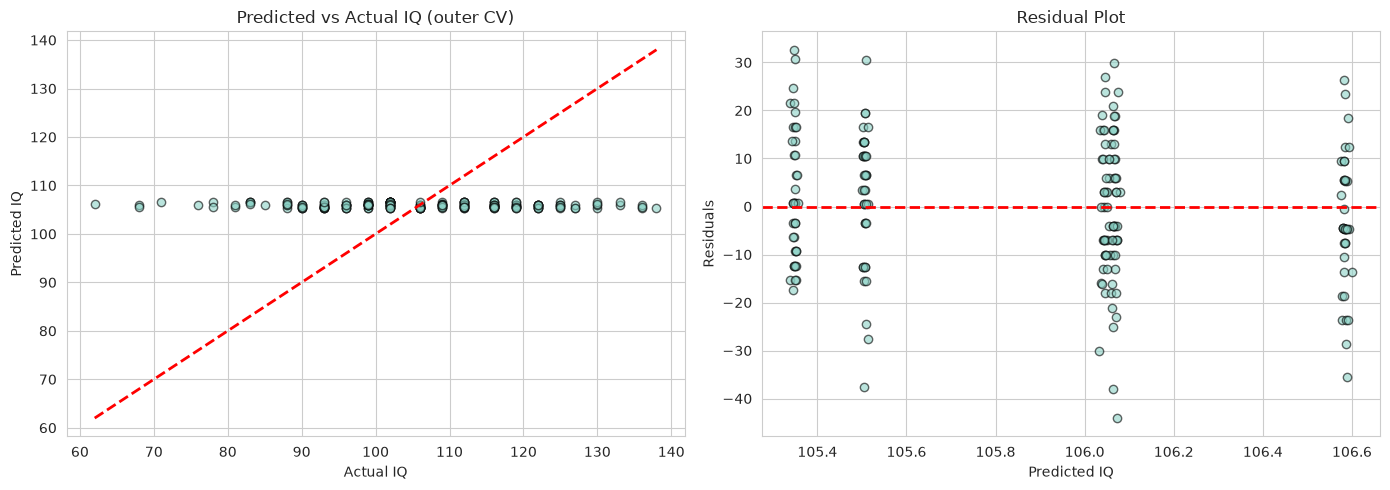

In [23]:
# --------------------------------------------------------------
# Predicted vs Actual and Residual plots
# --------------------------------------------------------------

y_pred = y_pred_viz
y_true = y_true_viz
residuals = y_true - y_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Predicted vs Actual (out-of-fold, outer CV)
axes[0].scatter(y_true, y_pred, alpha=0.6, edgecolors="k")
axes[0].plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], "r--", lw=2)
axes[0].set_xlabel("Actual IQ")
axes[0].set_ylabel("Predicted IQ")
axes[0].set_title("Predicted vs Actual IQ (outer CV)")

# Residuals
axes[1].scatter(y_pred, residuals, alpha=0.6, edgecolors="k")
axes[1].axhline(y=0, color="r", linestyle="--", lw=2)
axes[1].set_xlabel("Predicted IQ")
axes[1].set_ylabel("Residuals")
axes[1].set_title("Residual Plot")

plt.tight_layout()
plt.show()


## 8. Save / Load Model

Persist the trained model pipeline to disk for later inference.
Models are saved locally (not committed to repo — health data protection).


In [24]:
# --------------------------------------------------------------
# Save the trained pipeline
# --------------------------------------------------------------

joblib.dump(search_full.best_estimator_, f"regression_model_{TARGET_COLUMN}.pkl")
print(f"Best pipeline saved: regression_model_{TARGET_COLUMN}.pkl")


# --------------------------------------------------------------
# To load later:
# --------------------------------------------------------------

# loaded_pipeline = joblib.load(f"regression_model_{TARGET_COLUMN}.pkl")
# y_pred_loaded = loaded_pipeline.predict(X_new)


Best pipeline saved: regression_model_Note composite_WPPSI.pkl


---
## Next Steps

1. Confirm the target column name matches the cleaned merged dataset (case-sensitive).
2. Run all cells: load data → preprocess → train model → evaluate → visualize → save.
3. Try different models (Ridge, Lasso, Elastic Net, Random Forest, etc.) and compare.
4. Add hyperparameter tuning with nested cross-validation (inner CV for tuning, outer CV for performance).
5. Run `test_for_model.py` from the project root for the standardized cross-group comparison.
6. Report MAE and R² per `dataset.md` §9.
7. Per `GroupA/Plan for the Week.md` (Friday): review results, error analysis,
   compare to baseline (mean predictor), prepare tutor meeting, write `results/SUMMARY.md`.
